# H72: native 4k/6k coverage and GPU information pilot

One label-free CPU comparison, all57477originalrows. This measures input changes
and character exposure, not useful semantics, quality or runtime. The later GPU
stage is reported separately below. Original votes overlap public checkpoint training;
the prospective evaluation amendment uses local loss as a diagnostic and one
qualified frozen official trial as the target measurement.
[Coverage](../docs/SPAN_026_COVERAGE.md) · [Plan](../docs/SPAN_026_PLAN.md) ·
[Amendment](../docs/SPAN_026_EVALUATION_AMENDMENT.md).

Changed / total: 357 57477 ; fraction: 0.006211180124223602
CPU seconds: 539.3484105048701 ; CPU feasibility: True
Extra FULL-pass work / original G: 0.08985436461803732
Native control exact: True ; all old lengths exact: True


,field,total_chars,old_retained,new_retained,old_fraction,new_fraction
0,prompt,1494906,1259640,1405435,0.842622,0.940149
1,response_a,3589207,2612452,3263975,0.727863,0.909386
2,response_b,3660492,2361760,3243265,0.645203,0.886019


Old / new B absent: 25 3 ; newly visible B: 22


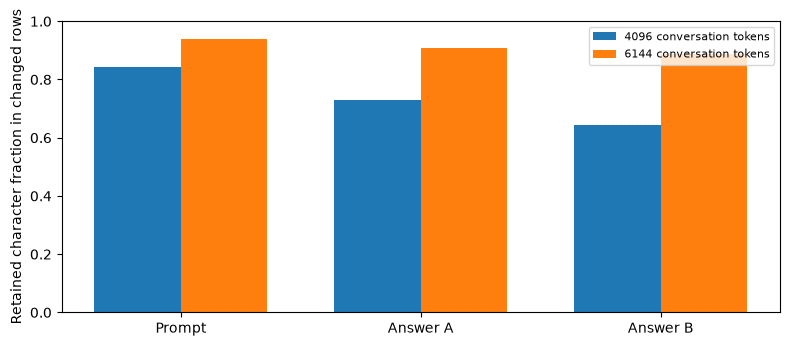

At the original CPU audit: quality measured: False ; GPU admitted: False
Later GPU stages are reported below; source work is not GPU runtime.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
r=json.loads((REPO/'results/span_026/coverage_audit.json').read_text())
print('Changed / total:',r['changed_rows'],r['rows'],'; fraction:',r['changed_fraction'])
print('CPU seconds:',r['elapsed_cpu_seconds'],'; CPU feasibility:',r['cpu_feasibility_passed'])
print('Extra FULL-pass work / original G:',r['extra_work_fraction_of_original_gemma'])
print('Native control exact:',r['canonical_control_tokens_exact'],'; all old lengths exact:',r['exact_original_lengths_reproduced'])
c=r['changed_character_coverage'];fields=['prompt','response_a','response_b']
table=pd.DataFrame([{'field':f,'total_chars':c['total_'+f],'old_retained':c['old_'+f],
 'new_retained':c['new_'+f],'old_fraction':c['old_'+f]/c['total_'+f],
 'new_fraction':c['new_'+f]/c['total_'+f]} for f in fields])
display(table)
print('Old / new B absent:',c['old_B_absent'],c['new_B_absent'],'; newly visible B:',c['newly_visible_B'])
fig,ax=plt.subplots(figsize=(8,3.5));x=np.arange(3)
ax.bar(x-.18,table.old_fraction,.36,label='4096 conversation tokens')
ax.bar(x+.18,table.new_fraction,.36,label='6144 conversation tokens')
ax.set_xticks(x,['Prompt','Answer A','Answer B']);ax.set_ylim(0,1)
ax.set_ylabel('Retained character fraction in changed rows');ax.legend(fontsize=8)
fig.tight_layout()
ROOT=Path.home()/'database/llm_classification_finetuning/runs/span_026'
(ROOT/'figures').mkdir(exist_ok=True)
fig.savefig(ROOT/'figures/context_coverage.png',dpi=160,bbox_inches='tight');plt.show()
print('At the original CPU audit: quality measured:',r['quality_measured'],'; GPU admitted:',r['gpu_admitted'])
print('Later GPU stages are reported below; source work is not GPU runtime.')

The early engineering observation comes from the live worker's aggregate log.
It is provisional until terminal retrieval and independent source/control checks.
The final qualification measures all three model roles. Neither runtime nor
training-overlapping loss is a hidden-score forecast.

In [2]:
PUB=REPO/'results/span_026'
prep=json.loads((PUB/'candidate_preparation.json').read_text())
print('Total label-free source CPU seconds:',prep['aggregate_cpu_source_seconds'],'/ 1200')
print('Qualification extra rows:',prep['changed_by_cohort'])
early=json.loads((PUB/'early_engineering_observation.json').read_text())
display(pd.DataFrame([{'stage':'Retained H60 projection','hours':30912.48602725137/3600},
 {'stage':'Provisional H72 early screen','hours':early['projection_seconds']/3600},
 {'stage':'Kaggle limit','hours':early['hidden_limit_seconds']/3600}]))
print('Early screen passed:',early['early_engineering_passed'],'; headroom seconds:',early['headroom_seconds'])
print('Observation:',early['observed_at'],'; independently audited:',early['independent_terminal_artifact_audit_complete'])
print('This observation is not full qualification or a score estimate.')
for filename in ['pilot_audit.json','candidate_qualification_replay.json']:
 path=PUB/filename
 if path.exists():
  result=json.loads(path.read_text())
  print(filename)
  display({k:v for k,v in result.items() if k in ['decision','complete_information','engineering_screen_passed',
   'weighted_lower_gain','weighted_upper_gain','weighted_lower_gain_paired_group95',
   'gross_regression_guard_passed','runtime_gate_passed','memory_guard_passed',
   'original_training_overlap','independent_cv','hidden_score_forecast','official_submission_eligible']})
  if 'slice_metrics' in result:display(pd.DataFrame(result['slice_metrics']).T)
  if 'runtime' in result:print('Actual qualification projection hours:',result['runtime']['projection_seconds']/3600)
  if 'validation_replay' in result:print('Original frozen validator failed derived-JS bitwise equality; rejected-only replay preserves raw1e-5controls and exact routes.')
 else:print(filename,': pending')
floor_path=PUB/'qualification_runtime_floor_replay.json'
if floor_path.exists():
 floor=json.loads(floor_path.read_text())
 print('QUALIFICATION RUNTIME FLOOR: candidate rejected for official deployment')
 print('Minimum projected hours:',floor['minimum_projection_seconds']/3600,'; cap:',floor['hidden_limit_seconds']/3600)
 print('Frozen-function replay passed:',floor['passed'],'; target labels used:',floor['uses_targets'])
 print('Unknown measurements enter only nonnegative maxima. This is a floor, not full terminal qualification.')
charges=[]
for role in ['context_pilot','context_qualification']:
 path=PUB/'jobs'/role/'controller_state.json'
 if path.exists():
  state=json.loads(path.read_text())
  if state['stage']=='complete':charges.append({'role':role,'charged_seconds':state['charged_seconds']})
if charges:display(pd.DataFrame(charges))
board_path=PUB/'final_leaderboard.json'
if board_path.exists():
 board=json.loads(board_path.read_text());print('Latest verified rank:',board['rank'],'/',board['teams'],'; retained official:',board['score'],'; checked:',board['observed_at'])

Total label-free source CPU seconds: 626.6421544449404 / 1200
Qualification extra rows: {'control': 3, 'uniform': 4, 'long': 63, 'test': 0}


,stage,hours
0,Retained H60 projection,8.586802
1,Provisional H72 early screen,8.903214
2,Kaggle limit,9.000000


Early screen passed: True ; headroom seconds: 348.43086067569675
Observation: 2026-11-08T17:33:16.763610+00:00 ; independently audited: False
This observation is not full qualification or a score estimate.
pilot_audit.json


{'complete_information': True,
 'engineering_screen_passed': True,
 'weighted_lower_gain': -0.00023435647974239863,
 'weighted_upper_gain': 0.0001223668497754013,
 'weighted_lower_gain_paired_group95': [-0.0003178126982293481,
  -0.00015257430574821333],
 'gross_regression_guard_passed': True,
 'original_training_overlap': True,
 'independent_cv': False,
 'hidden_score_forecast': False,
 'decision': 'prepare_actual_full_qualification',
 'official_submission_eligible': False}

,log_loss,accuracy,brier,class_log_loss,class_recall,mean_probabilities
parent_off,0.884017,0.596639,0.521724,"{'winner_model_a': 0.8181489351750133, 'winner...","{'winner_model_a': 0.6850393700787402, 'winner...","[0.351061, 0.351964, 0.296975]"
candidate_off,0.897547,0.591036,0.532203,"{'winner_model_a': 0.8153127551564673, 'winner...","{'winner_model_a': 0.7165354330708661, 'winner...","[0.353685, 0.319606, 0.326709]"
parent_on,0.880353,0.619048,0.51904,"{'winner_model_a': 0.8197797314965988, 'winner...","{'winner_model_a': 0.7007874015748031, 'winner...","[0.349522, 0.353672, 0.296806]"
candidate_on,0.884853,0.607843,0.52274,"{'winner_model_a': 0.817155767026594, 'winner_...","{'winner_model_a': 0.7165354330708661, 'winner...","[0.350834, 0.337493, 0.311673]"


candidate_qualification_replay.json


{'runtime_gate_passed': False,
 'memory_guard_passed': True,
 'original_training_overlap': True,
 'independent_cv': False,
 'hidden_score_forecast': False,
 'official_submission_eligible': False}

Actual qualification projection hours: 9.446577790460916
Original frozen validator failed derived-JS bitwise equality; rejected-only replay preserves raw1e-5controls and exact routes.
QUALIFICATION RUNTIME FLOOR: candidate rejected for official deployment
Minimum projected hours: 9.14722653878832 ; cap: 9.0
Frozen-function replay passed: True ; target labels used: False
Unknown measurements enter only nonnegative maxima. This is a floor, not full terminal qualification.


,role,charged_seconds
0,context_pilot,5461.312
1,context_qualification,2442.451


Latest verified rank: 23 / 310 ; retained official: 0.82987 ; checked: 2026-11-08T19:43:55.230601+00:00
